# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [2]:
data = pd.read_csv("thyroidDF.csv")

In [3]:
data.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


In [4]:
data.shape

(9172, 31)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9172 entries, 0 to 9171
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  9172 non-null   int64  
 1   sex                  8865 non-null   str    
 2   on_thyroxine         9172 non-null   str    
 3   query_on_thyroxine   9172 non-null   str    
 4   on_antithyroid_meds  9172 non-null   str    
 5   sick                 9172 non-null   str    
 6   pregnant             9172 non-null   str    
 7   thyroid_surgery      9172 non-null   str    
 8   I131_treatment       9172 non-null   str    
 9   query_hypothyroid    9172 non-null   str    
 10  query_hyperthyroid   9172 non-null   str    
 11  lithium              9172 non-null   str    
 12  goitre               9172 non-null   str    
 13  tumor                9172 non-null   str    
 14  hypopituitary        9172 non-null   str    
 15  psych                9172 non-null   str    
 16 

In [6]:
data.describe()

,age,TSH,T3,TT4,T4U,FTI,TBG,patient_id
count,9172.000000,8330.000000,6568.000000,8730.000000,8363.000000,8370.000000,349.000000,9.172000e+03
mean,73.555822,5.218403,1.970629,108.700305,0.976056,113.640746,29.870057,8.529473e+08
std,1183.976718,24.184006,0.887579,37.522670,0.200360,41.551650,21.080504,7.581969e+06
min,1.000000,0.005000,0.050000,2.000000,0.170000,1.400000,0.100000,8.408010e+08
25%,37.000000,0.460000,1.500000,87.000000,0.860000,93.000000,21.000000,8.504090e+08
50%,55.000000,1.400000,1.900000,104.000000,0.960000,109.000000,26.000000,8.510040e+08
75%,68.000000,2.700000,2.300000,126.000000,1.065000,128.000000,31.000000,8.607110e+08
max,65526.000000,530.000000,18.000000,600.000000,2.330000,881.000000,200.000000,8.701190e+08


In [7]:
data.isnull().sum()

age                       0
sex                     307
on_thyroxine              0
query_on_thyroxine        0
on_antithyroid_meds       0
sick                      0
pregnant                  0
thyroid_surgery           0
I131_treatment            0
query_hypothyroid         0
query_hyperthyroid        0
lithium                   0
goitre                    0
tumor                     0
hypopituitary             0
psych                     0
TSH_measured              0
TSH                     842
T3_measured               0
T3                     2604
TT4_measured              0
TT4                     442
T4U_measured              0
T4U                     809
FTI_measured              0
FTI                     802
TBG_measured              0
TBG                    8823
referral_source           0
target                    0
patient_id                0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data = data.rename(columns={
    "age": "Age",
    "sex": "Gender",
    "on_thyroxine": "Taking_Thyroxine",
    "query_on_thyroxine": "Thyroxine_Query",
    "on_antithyroid_meds": "Taking_Antithyroid_Medicine",
    "sick": "Is_Sick",
    "pregnant": "Is_Pregnant",
    "thyroid_surgery": "Had_Thyroid_Surgery",
    "I131_treatment": "Radioiodine_Treatment",
    "query_hypothyroid": "Suspected_Hypothyroid",
    "query_hyperthyroid": "Suspected_Hyperthyroid",
    "lithium": "Taking_Lithium",
    "goitre": "Has_Goitre",
    "tumor": "Has_Tumor",
    "hypopituitary": "Has_Pituitary_Problem",
    "psych": "Psychiatric_Flag",
    "TSH_measured": "TSH_Tested",
    "T3_measured": "T3_Tested",
    "TT4_measured": "TT4_Tested",
    "T4U_measured": "T4U_Tested",
    "FTI_measured": "FTI_Tested",
    "TBG_measured": "TBG_Tested",
    "referral_source": "Referral_Source",
    "target": "Diagnosis",
    "patient_id": "Patient_ID"
})

In [10]:
data.columns

Index(['Age', 'Gender', 'Taking_Thyroxine', 'Thyroxine_Query',
       'Taking_Antithyroid_Medicine', 'Is_Sick', 'Is_Pregnant',
       'Had_Thyroid_Surgery', 'Radioiodine_Treatment', 'Suspected_Hypothyroid',
       'Suspected_Hyperthyroid', 'Taking_Lithium', 'Has_Goitre', 'Has_Tumor',
       'Has_Pituitary_Problem', 'Psychiatric_Flag', 'TSH_Tested', 'TSH',
       'T3_Tested', 'T3', 'TT4_Tested', 'TT4', 'T4U_Tested', 'T4U',
       'FTI_Tested', 'FTI', 'TBG_Tested', 'TBG', 'Referral_Source',
       'Diagnosis', 'Patient_ID'],
      dtype='str')

In [11]:
data.head()

,Age,Gender,Taking_Thyroxine,Thyroxine_Query,Taking_Antithyroid_Medicine,Is_Sick,Is_Pregnant,Had_Thyroid_Surgery,Radioiodine_Treatment,Suspected_Hypothyroid,...,TT4,T4U_Tested,T4U,FTI_Tested,FTI,TBG_Tested,TBG,Referral_Source,Diagnosis,Patient_ID
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


In [12]:
data = data.drop(columns=["Patient_ID", "TBG", "TBG_Tested", "Referral_Source"])

In [13]:
data.shape

(9172, 27)

# EDA : Exploratory Data Analysis

In [14]:
data.isnull().sum()

Age                               0
Gender                          307
Taking_Thyroxine                  0
Thyroxine_Query                   0
Taking_Antithyroid_Medicine       0
Is_Sick                           0
Is_Pregnant                       0
Had_Thyroid_Surgery               0
Radioiodine_Treatment             0
Suspected_Hypothyroid             0
Suspected_Hyperthyroid            0
Taking_Lithium                    0
Has_Goitre                        0
Has_Tumor                         0
Has_Pituitary_Problem             0
Psychiatric_Flag                  0
TSH_Tested                        0
TSH                             842
T3_Tested                         0
T3                             2604
TT4_Tested                        0
TT4                             442
T4U_Tested                        0
T4U                             809
FTI_Tested                        0
FTI                             802
Diagnosis                         0
dtype: int64

In [15]:
data["Age"].describe()

count     9172.000000
mean        73.555822
std       1183.976718
min          1.000000
25%         37.000000
50%         55.000000
75%         68.000000
max      65526.000000
Name: Age, dtype: float64

In [16]:
data["Age"].sort_values(ascending=False).head(10)

8105    65526
6392    65512
5710    65511
2976      455
790        97
7356       97
7355       97
8155       95
5758       95
8968       95
Name: Age, dtype: int64

In [17]:
data[data["Age"] > 110][["Age", "Diagnosis"]]

,Age,Diagnosis
2976,455,-
5710,65511,-
6392,65512,-
8105,65526,-


In [18]:
data["Age"] = data["Age"].where(data["Age"].between(0, 110))

In [19]:
data.Age.median(), data.Age.mean()

(55.0, np.float64(52.099694589877835))

In [20]:
data["Age"].describe()

count    9168.000000
mean       52.099695
std        18.910296
min         1.000000
25%        37.000000
50%        55.000000
75%        67.000000
max        97.000000
Name: Age, dtype: float64

In [21]:
data[data["Age"] > 110]

,Age,Gender,Taking_Thyroxine,Thyroxine_Query,Taking_Antithyroid_Medicine,Is_Sick,Is_Pregnant,Had_Thyroid_Surgery,Radioiodine_Treatment,Suspected_Hypothyroid,...,TSH,T3_Tested,T3,TT4_Tested,TT4,T4U_Tested,T4U,FTI_Tested,FTI,Diagnosis


In [22]:
data["Diagnosis"].value_counts()

Diagnosis
-      6771
K       436
G       359
I       346
F       233
R       196
A       147
L       115
M       111
N       110
S        85
GK       49
AK       46
J        30
B        21
MK       16
Q        14
O        14
C|I      12
KJ       11
GI       10
H|K       8
D         8
FK        6
C         6
P         5
MI        2
LJ        1
GKJ       1
OI        1
D|R       1
E         1
Name: count, dtype: int64

In [23]:
data["Diagnosis"].unique()

<ArrowStringArray>
[  '-',   'S',   'F',  'AK',   'R',   'I',   'M',   'N',   'G',   'K',   'A',
  'KJ',   'L',  'MK',   'Q',   'J', 'C|I',   'O',  'LJ', 'H|K',   'D',  'GK',
  'MI',   'P',  'FK',   'B',  'GI',   'C', 'GKJ',  'OI', 'D|R',   'E']
Length: 32, dtype: str

In [24]:
data["Diagnosis"].nunique()

32

# Graphs

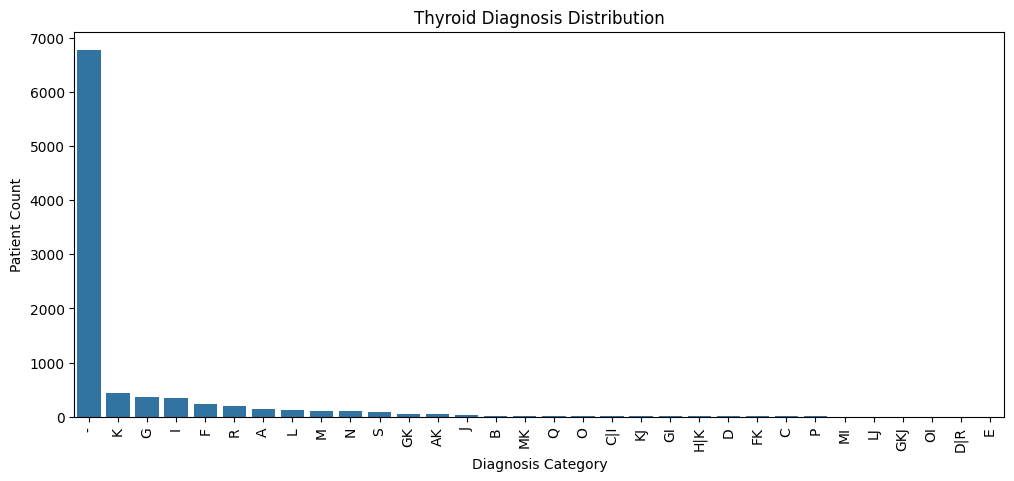

In [25]:
plt.figure(figsize=(12, 5))

sns.countplot(data=data, x="Diagnosis", order=data["Diagnosis"].value_counts().index)

plt.title("Thyroid Diagnosis Distribution")
plt.xlabel("Diagnosis Category")
plt.ylabel("Patient Count")
plt.xticks(rotation=90)
plt.show()

# Histogram

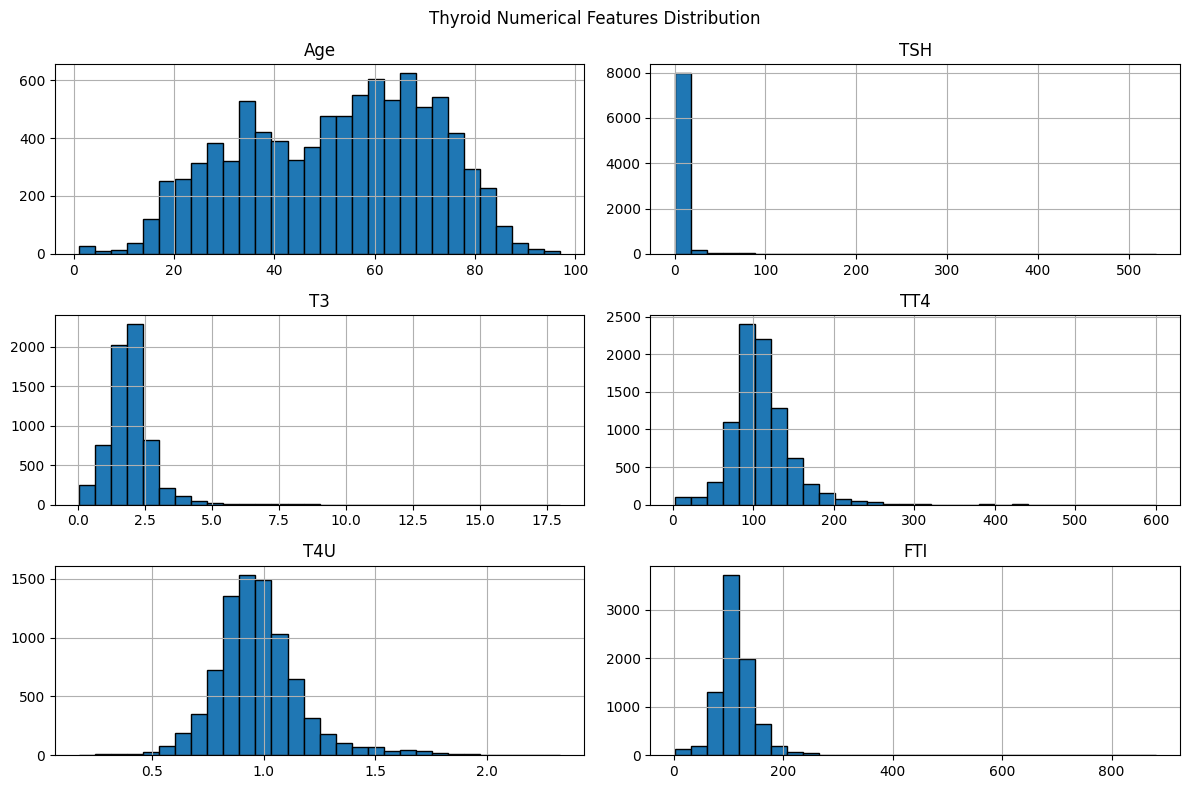

In [26]:
numeric_cols = ["Age", "TSH", "T3", "TT4", "T4U", "FTI"]

data[numeric_cols].hist(figsize=(12, 8), bins=30, edgecolor="black")

plt.suptitle("Thyroid Numerical Features Distribution")
plt.tight_layout()
plt.show()

# Boxplot

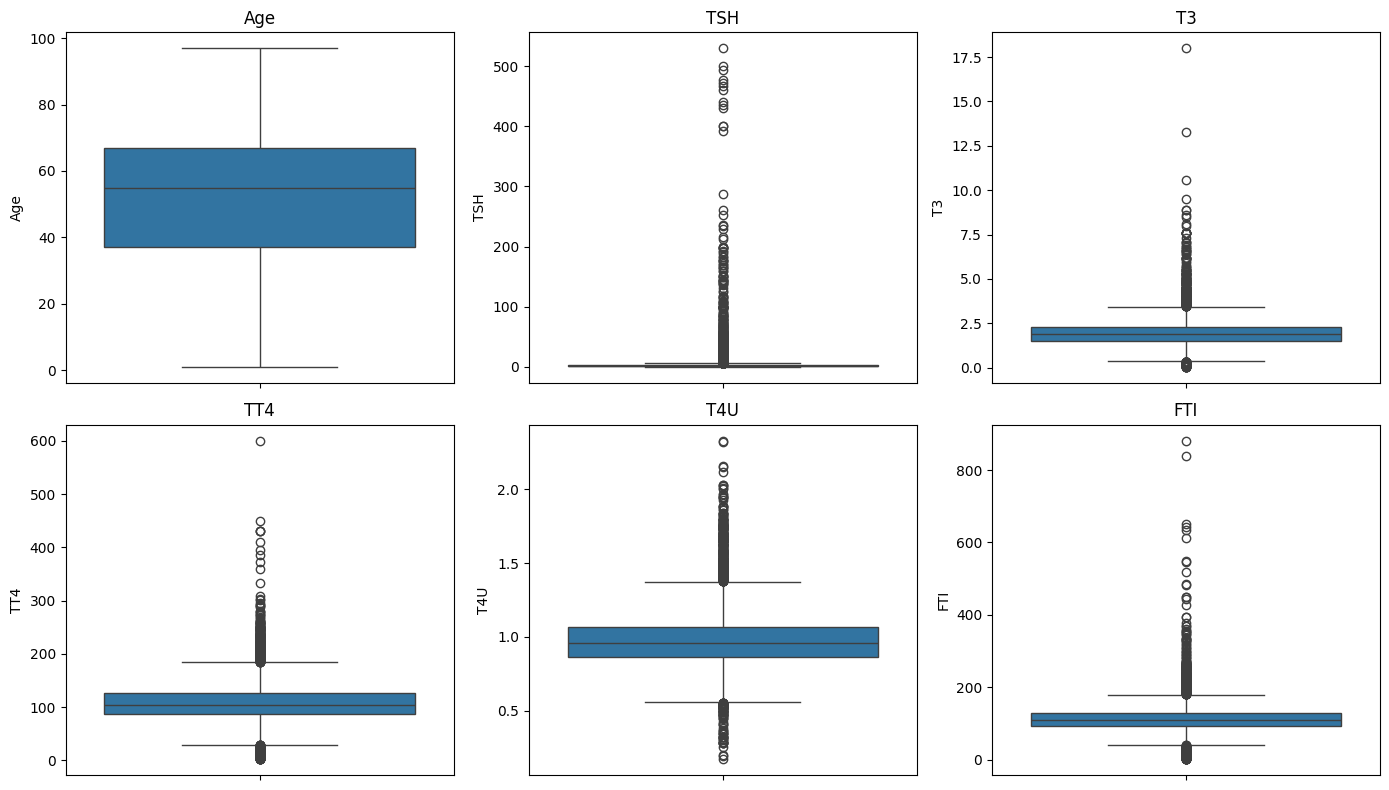

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# Heatmap

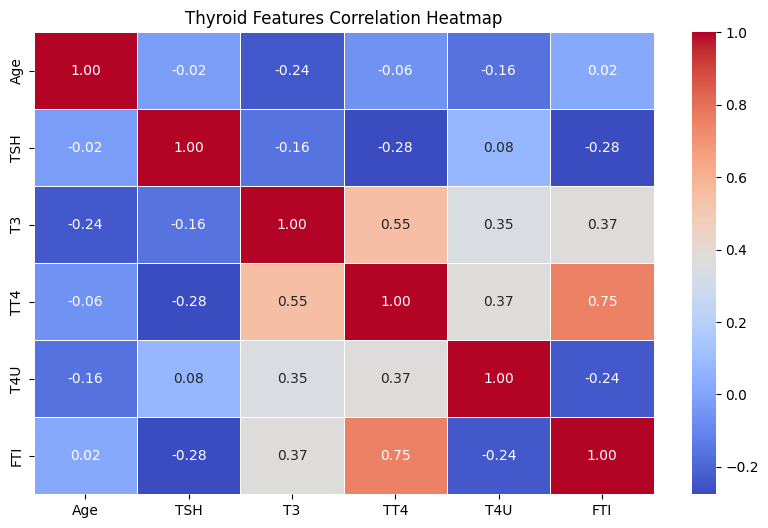

In [28]:
plt.figure(figsize=(10, 6))

sns.heatmap(data[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Thyroid Features Correlation Heatmap")
plt.show()

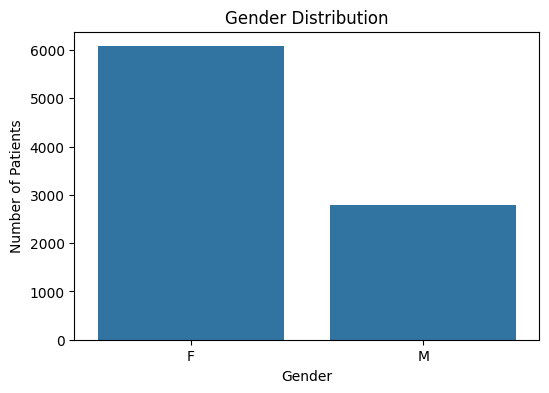

In [29]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="Gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()

In [30]:
data["Disease"] = data["Diagnosis"].apply(lambda x: 0 if x == "-" else 1)

In [31]:
data["Disease"].value_counts()

Disease
0    6771
1    2401
Name: count, dtype: int64

# Plot Binary Target Distribution

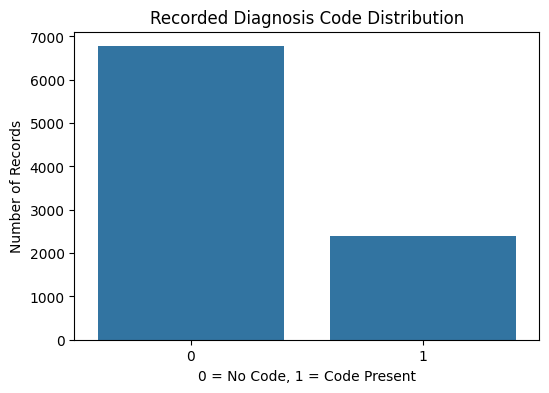

In [32]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="Disease")

plt.title("Recorded Diagnosis Code Distribution")
plt.xlabel("0 = No Code, 1 = Code Present")
plt.ylabel("Number of Records")
plt.show()

In [33]:
X = data[["Age", "Gender", "TSH", "T3", "TT4", "FTI"]].copy()

In [34]:
y = data["Disease"]

In [35]:
X["Gender"] = X["Gender"].map({"F": 0, "M": 1})

In [36]:
X.head()

,Age,Gender,TSH,T3,TT4,FTI
0,29.0,0.0,0.3,NaN,NaN,NaN
1,29.0,0.0,1.6,1.9,128.0,NaN
2,41.0,0.0,NaN,NaN,NaN,NaN
3,36.0,0.0,NaN,NaN,NaN,NaN
4,32.0,0.0,NaN,NaN,NaN,NaN


In [37]:
X.select_dtypes(include="object").columns

Index([], dtype='str')

# Train Test Split

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [40]:
print("Training Shape:", X_train.shape)

Training Shape: (7337, 6)


In [41]:
print("Testing Shape:", X_test.shape)

Testing Shape: (1835, 6)


# Build Gradient Boosting model

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

In [43]:
median_cols = ["Age", "TSH", "T3", "TT4", "FTI"]

In [44]:

mode_col = ["Gender"]

In [45]:
preprocessor = ColumnTransformer([
    (
        "median",
        SimpleImputer(strategy="median"),
        median_cols
    ),
    (
        "mode",
        SimpleImputer(strategy="most_frequent"),
        mode_col
    )
])

In [46]:
model = Pipeline([("preprocessing", preprocessor),("classifier", GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))])

# Train Model

In [47]:
model.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('median', ...), ('mode', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# Prediction 

In [48]:
model.predict(X_test)

array([0, 0, 0, ..., 1, 0, 0], shape=(1835,))

In [49]:
y_pred = model.predict(X_test)

# Model Evaluation

In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [51]:
accuracy_score(y_test, y_pred)

0.9362397820163487

In [52]:
precision_score(y_test, y_pred, zero_division=0)

0.8989010989010989

In [53]:
recall_score(y_test, y_pred, zero_division=0)

0.8520833333333333

In [54]:
f1_score(y_test, y_pred, zero_division=0)

0.8748663101604278

In [55]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1355
           1       0.90      0.85      0.87       480

    accuracy                           0.94      1835
   macro avg       0.92      0.91      0.92      1835
weighted avg       0.94      0.94      0.94      1835



# Confusion Matrix

In [56]:
cm = confusion_matrix(y_test, y_pred)

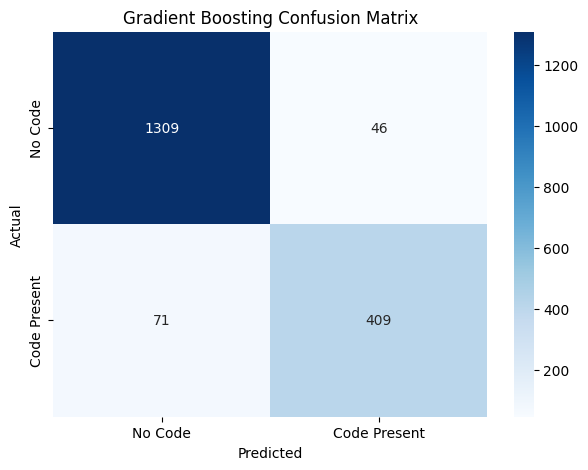

In [57]:
plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Code", "Code Present"], yticklabels=["No Code", "Code Present"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

# Prediction Error Analysis

In [58]:
errors = y_test.to_numpy() - y_pred

In [59]:
errors

array([0, 0, 0, ..., 0, 0, 0], shape=(1835,))

In [60]:
results = pd.DataFrame({"Actual": y_test.to_numpy(), "Predicted": y_pred, "Error": errors})

In [61]:
results

,Actual,Predicted,Error
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,1,1,0
...,...,...,...
1830,0,0,0
1831,1,1,0
1832,1,1,0
1833,0,0,0


In [62]:
wrong = results[results["Error"] != 0]

In [63]:
print("Total Wrong Predictions:", len(wrong))

Total Wrong Predictions: 117


In [64]:
wrong

,Actual,Predicted,Error
32,0,1,-1
73,0,1,-1
83,1,0,1
95,0,1,-1
97,1,0,1
...,...,...,...
1768,1,0,1
1782,1,0,1
1785,0,1,-1
1804,1,0,1


# Error Distribution Graph

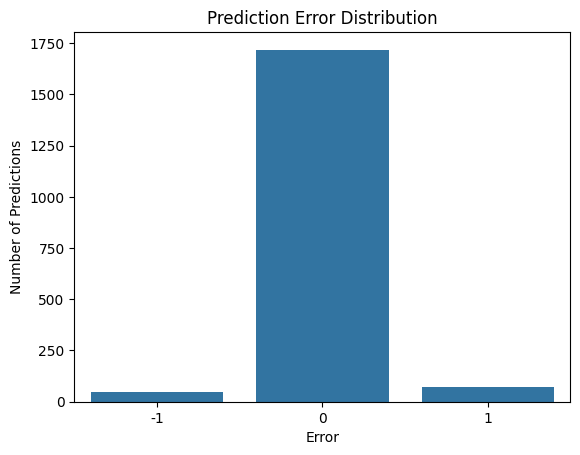

In [65]:
sns.countplot(data=results, x="Error")

plt.title("Prediction Error Distribution")
plt.xlabel("Error")
plt.ylabel("Number of Predictions")
plt.show()

# Patient Prediction Function

In [70]:
def predict_thyroid(patient):

    inp = pd.DataFrame([patient]).reindex(columns=X.columns)

    result = model.predict(inp)

    if result[0] == 1:
        return "Diagnosis code present"
    else:
        return "No diagnosis code"

In [71]:
patient = X_test.iloc[0].to_dict()

In [72]:
print(predict_thyroid(patient))

No diagnosis code


# Manual Prediction

In [75]:
patient = {}

number_cols = ["Age", "TSH", "T3", "TT4", "FTI"]

for col in X.columns:
    value = input(f"Enter {col}: ").strip()
    if value == "":
        patient[col] = np.nan
    elif col == "Gender":
        patient[col] = {"M": 1, "F": 0}[value.upper()]
    elif col in number_cols:
        patient[col] = float(value)
    else:
        patient[col] = {"T": 1, "F": 0}[value.upper()]

print(predict_thyroid(patient))

Enter Age:  22
Enter Gender:  M
Enter TSH:  1.8
Enter T3:  1.5
Enter TT4:  105
Enter FTI:  110


No diagnosis code


# Save the Model

In [76]:
import joblib

In [77]:
joblib.dump(model, "thyroid_disease.pkl")

['thyroid_disease.pkl']

In [78]:
model = joblib.load("thyroid_disease.pkl")

In [79]:
print(model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('median',
                                                  SimpleImputer(strategy='median'),
                                                  ['Age', 'TSH', 'T3', 'TT4',
                                                   'FTI']),
                                                 ('mode',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['Gender'])])),
                ('classifier', GradientBoostingClassifier(random_state=42))])


# Check prediction

In [80]:
prediction = model.predict(X_test.iloc[[3]])

In [81]:
print("Prediction:", prediction[0])

Prediction: 0
